# MSD Task03 Liver: разведочный анализ

Источник — [MSD Task03 Liver](https://registry.opendata.aws/msd/), представление LiTS
(лицензия CC-BY-SA 4.0). [Исходный архив](https://msd-for-monai.s3-us-west-2.amazonaws.com/Task03_Liver.tar).

## 1. Подготовка

In [43]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np
import pandas as pd
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from scipy import ndimage as ndi
from tqdm.auto import tqdm

ROOT = Path.cwd()
if ROOT.name == 'analytics':
    ROOT = ROOT.parent

DATA = ROOT / 'data/raw/msd_task03_liver/Task03_Liver'
GEOMETRY_FIXES = ROOT / 'data/interim/msd_task03_liver/ircad_geometry_corrections.json'
SEED = 2222

plt.rcParams.update({
    'font.size': 11,
    'figure.figsize': (10, 4.5),
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.formatter.useoffset': False,
})

## 2. Геометрия КТ и масок

Сначала проверим размеры, шаг вокселей, единицы измерения и affine — матрицу перехода
от индексов вокселей к физическим координатам. У КТ и её маски геометрия должна совпадать.

### 2.1. Поправки для исследований IRCAD

Для `liver_28`–`liver_47` используем таблицу
`ircad_geometry_corrections.json`: она восстанавливает геометрию по
[DICOM IRCAD](https://www.ircad.fr/research-and-development/data-sets/liver-segmentation-3d-ircadb-01/).
В ней сохранены параметры и результаты сопоставления с исходными КТ, включая порядок осей
и ограничение HU снизу до −1024 в части файлов MSD.

In [4]:
with open(GEOMETRY_FIXES) as f:
    geometry_fixes = json.load(f)['cases']


def load_image(path):
    """Читаем NIfTI; для проверенных случаев восстанавливаем геометрию в памяти."""
    path = Path(path)
    image = nib.load(path)
    case_id = path.name.removesuffix('.nii.gz')
    fix = geometry_fixes.get(case_id)
    train_folders = [(DATA / folder).resolve() for folder in ['imagesTr', 'labelsTr']]
    if fix is None or path.parent.resolve() not in train_folders:
        return image

    # Поправка относится только к исходной версии файлов MSD.
    if list(image.shape) != fix['expected_shape']:
        raise ValueError(f'{case_id}: размер файла отличается от проверенного')
    if not np.allclose(image.affine, fix['raw_affine_ras'], rtol=0, atol=1e-6):
        raise ValueError(f'{case_id}: исходная геометрия изменилась; нужна повторная проверка')
    if not np.allclose(image.header.get_zooms(), fix['raw_spacing_mm'], rtol=0, atol=1e-6):
        raise ValueError(f'{case_id}: исходный шаг вокселей изменился')

    affine = np.array(fix['affine_ras'], dtype=float)
    corrected = nib.Nifti1Image(image.dataobj, affine, image.header.copy())
    corrected.set_sform(affine, code=1)
    corrected.set_qform(affine, code=1, strip_shears=False)
    corrected.header.set_xyzt_units('mm', image.header.get_xyzt_units()[1])
    return corrected

In [5]:
rows = []
for folder, split in [('imagesTr', 'train'), ('imagesTs', 'test')]:
    for path in sorted((DATA / folder).glob('*.nii.gz')):
        if path.name.startswith('._'):
            continue
        raw_image = nib.load(path)  # сохраняем исходную геометрию для сравнения
        raw_spacing = raw_image.header.get_zooms()
        image = load_image(path)
        case_id = path.name.removesuffix('.nii.gz')
        label_path = DATA / 'labelsTr' / path.name if split == 'train' else None
        spacing = image.header.get_zooms()
        shape_ok = affine_ok = affine_ok_raw = True
        units_ok = image.header.get_xyzt_units()[0] == 'mm'

        if label_path is not None:
            raw_label = nib.load(label_path)
            label = load_image(label_path)
            shape_ok = image.shape == label.shape
            affine_ok_raw = np.allclose(
                raw_image.affine, raw_label.affine, atol=1e-4, rtol=0
            )
            affine_ok = np.allclose(image.affine, label.affine, atol=1e-4, rtol=0)
            units_ok = units_ok and label.header.get_xyzt_units()[0] == 'mm'

        corrected = split == 'train' and case_id in geometry_fixes
        rows.append({
            'case_id': case_id,
            'split': split,
            'image': path,
            'label': label_path,
            'nx': image.shape[0],
            'ny': image.shape[1],
            'nz': image.shape[2],
            'sx_mm': spacing[0],
            'sy_mm': spacing[1],
            'sz_mm': spacing[2],
            'sx_mm_raw': raw_spacing[0],
            'sy_mm_raw': raw_spacing[1],
            'sz_mm_raw': raw_spacing[2],
            'orientation': ''.join(nib.aff2axcodes(image.affine)),
            'orientation_raw': ''.join(nib.aff2axcodes(raw_image.affine)),
            'voxel_mm3': abs(np.linalg.det(image.affine[:3, :3])),
            'voxel_mm3_raw': abs(np.linalg.det(raw_image.affine[:3, :3])),
            'geometry_corrected': corrected,
            'geometry_source': 'IRCAD DICOM' if corrected else 'NIfTI',
            'shape_ok': shape_ok,
            'affine_ok': affine_ok,
            'affine_ok_raw': affine_ok_raw,
            'units_ok': units_ok,
        })

headers = pd.DataFrame(rows)

In [6]:
train = headers[headers.split == 'train'].copy()
test = headers[headers.split == 'test'].copy()

In [7]:
geometry_checks = pd.Series({
    'Пар КТ/маска': len(train),
    'Несовпадений размеров': int((~train.shape_ok).sum()),
    'Несовпадений affine до поправок': int((~train.affine_ok_raw).sum()),
    'Несовпадений affine после поправок': int((~train.affine_ok).sum()),
    'КТ с единицами, отличными от мм': int((~headers.units_ok).sum()),
    'КТ с поправкой IRCAD': int(train.geometry_corrected.sum()),
}, name='Количество')
assert train[['shape_ok', 'affine_ok']].all().all(), 'Геометрия КТ и маски не совпадает'
assert headers.units_ok.all(), 'Единицы измерения должны быть мм'
geometry_checks.to_frame()

,Количество
Пар КТ/маска,131
Несовпадений размеров,0
Несовпадений affine до поправок,0
Несовпадений affine после поправок,0
"КТ с единицами, отличными от мм",0
КТ с поправкой IRCAD,20


In [8]:
headers.loc[
    headers.geometry_corrected,
    [
        'case_id', 'sx_mm_raw', 'sy_mm_raw', 'sz_mm_raw',
        'sx_mm', 'sy_mm', 'sz_mm', 'geometry_source',
    ],
].round(6)

,case_id,sx_mm_raw,sy_mm_raw,sz_mm_raw,sx_mm,sy_mm,sz_mm,geometry_source
52,liver_28,1.0,1.0,1.0,0.570000,0.570000,1.60,IRCAD DICOM
53,liver_29,1.0,1.0,1.0,0.782000,0.782000,1.60,IRCAD DICOM
55,liver_30,1.0,1.0,1.0,0.625000,0.625000,1.25,IRCAD DICOM
56,liver_31,1.0,1.0,1.0,0.742188,0.742188,2.00,IRCAD DICOM
57,liver_32,1.0,1.0,1.0,0.782000,0.782000,1.60,IRCAD DICOM
58,liver_33,1.0,1.0,1.0,0.782000,0.782000,1.60,IRCAD DICOM
59,liver_34,1.0,1.0,1.0,0.782000,0.782000,1.60,IRCAD DICOM
60,liver_35,1.0,1.0,1.0,0.561000,0.561000,1.60,IRCAD DICOM
61,liver_36,1.0,1.0,1.0,0.873047,0.873047,2.00,IRCAD DICOM
62,liver_37,1.0,1.0,1.0,0.736000,0.736000,1.60,IRCAD DICOM


In [9]:
train[['nz', 'sx_mm', 'sy_mm', 'sz_mm']].describe().round(3)

,nz,sx_mm,sy_mm,sz_mm
count,131.000,131.000,131.000,131.000
mean,447.618,0.751,0.751,1.625
std,275.250,0.084,0.084,1.182
min,74.000,0.557,0.557,0.700
25%,190.000,0.691,0.691,0.800
50%,432.000,0.744,0.744,1.200
75%,684.000,0.784,0.784,2.000
max,987.000,0.977,0.977,5.000


Геометрия всех 131 пар согласована; для 20 КТ учтены поправки IRCAD.
Шаг по z меняется примерно от 0,7 до 5 мм — единой исходной сетки нет.

### 2.2. Физические размеры

Размер области сканирования равен числу вокселей, умноженному на их шаг.
Это протяжённость КТ вдоль осей сетки, а не размер печени.
Размеры по x и y совпадают, поэтому на графике оставим x и z.

In [10]:
ct_sizes = train[['case_id']].copy()
for axis in ['x', 'y', 'z']:
    ct_sizes[f'{axis}_mm'] = train[f'n{axis}'] * train[f's{axis}_mm']

ct_sizes[['x_mm', 'y_mm', 'z_mm']].agg(['min', 'median', 'max']).T.rename(
    index={
        'x_mm': 'Ширина по x, мм',
        'y_mm': 'Высота по y, мм',
        'z_mm': 'Длина по z, мм',
    },
    columns={'min': 'Минимум', 'median': 'Медиана', 'max': 'Максимум'},
).round(1)

,Минимум,Медиана,Максимум
"Ширина по x, мм",285.0,381.0,500.0
"Высота по y, мм",285.0,381.0,500.0
"Длина по z, мм",180.8,484.0,807.7


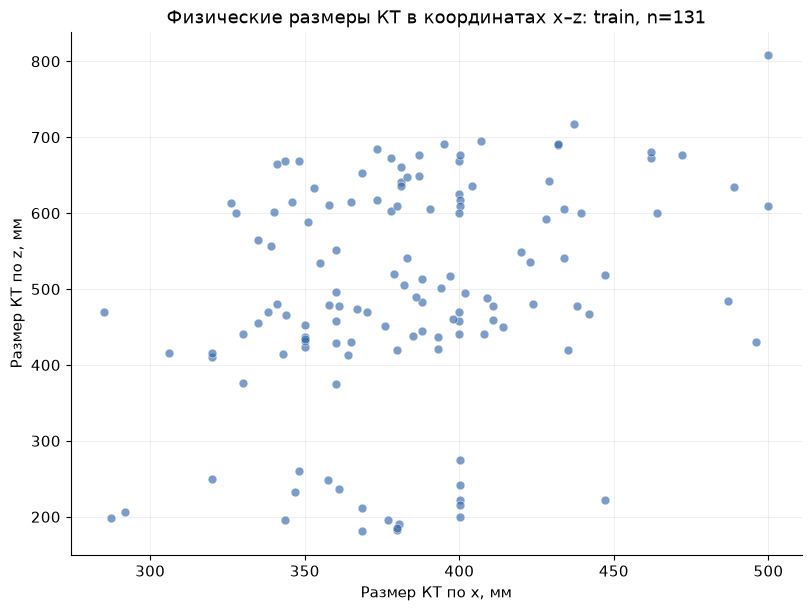

In [11]:
fig, ax = plt.subplots(figsize=(8, 6), layout='constrained')
ax.scatter(
    ct_sizes['x_mm'], ct_sizes['z_mm'],
    s=40, color='#3569AD', alpha=0.65, edgecolors='white', linewidths=0.5,
)
ax.set_xlabel('Размер КТ по x, мм')
ax.set_ylabel('Размер КТ по z, мм')
ax.set_title(f'Физические размеры КТ в координатах x–z: train, n={len(ct_sizes)}')
ax.set_axisbelow(True)
ax.grid(alpha=0.2)
plt.show()

Длина КТ по z составляет 180,8–807,7 мм, медиана — 484 мм.

### 3.3. Сравнение train и test

Сравним все КТ после поправок. Доли считаем отдельно внутри train и test.

In [12]:
geometry_summary = pd.DataFrame(index=[
    'Число срезов по z, медиана',
    'Шаг по x, мм, медиана',
    'Шаг по z, мм, медиана',
    'КТ с шагом по z ≤ 1,5 мм, %',
    'КТ с шагом по z ≈ 5 мм, %',
])

for name, group in [('Train', train), ('Test', test)]:
    geometry_summary[f'{name} (n={len(group)})'] = [
        f'{group.nz.median():g}',
        f'{group.sx_mm.median():.3f}',
        f'{group.sz_mm.median():.2f}',
        f'{100 * (group.sz_mm <= 1.5).mean():.1f}',
        f'{100 * np.isclose(group.sz_mm, 5).mean():.1f}',
    ]

geometry_summary

,Train (n=131),Test (n=70)
"Число срезов по z, медиана",432,285.5
"Шаг по x, мм, медиана",0.744,0.742
"Шаг по z, мм, медиана",1.20,1.75
"КТ с шагом по z ≤ 1,5 мм, %",61.1,50.0
"КТ с шагом по z ≈ 5 мм, %",6.9,21.4


В test чаще встречается шаг по z около 5 мм: 21,4% против 6,9% в train.
Геометрия выборок различается, особенно по шагу между срезами.

## 3. Маски и объёмы

Проверим метки во всех 131 маске. Объём в мл — число вокселей × объём вокселя в мм³ / 1000.
Для дисбаланса посмотрим долю опухоли и в печени с опухолью, и во всей КТ.

In [13]:
selected = train.sort_values('case_id').copy()

In [14]:
rows = []
for case in selected.itertuples():
    mask = np.asarray(load_image(case.label).dataobj)
    labels = np.unique(mask)
    assert np.isin(labels, [0, 1, 2]).all(), f'{case.case_id}: неожиданные метки {labels}'
    liver_voxels = np.count_nonzero(mask == 1)
    tumor_voxels = np.count_nonzero(mask == 2)
    organ_voxels = liver_voxels + tumor_voxels
    rows.append({
        'case_id': case.case_id,
        'labels': labels.tolist(),
        'liver_only_ml': liver_voxels * case.voxel_mm3 / 1000,
        'organ_ml': organ_voxels * case.voxel_mm3 / 1000,
        'tumor_ml': tumor_voxels * case.voxel_mm3 / 1000,
        'tumor_pct_organ': 100 * tumor_voxels / organ_voxels if organ_voxels else np.nan,
        'tumor_pct_scan': 100 * tumor_voxels / mask.size,
        'tumor_slices': np.count_nonzero(np.any(mask == 2, axis=(0, 1))),
    })

stats = pd.DataFrame(rows)
print('Без размеченной опухоли:', (stats.tumor_ml == 0).sum())
print('С пустой маской органа:', (stats.organ_ml == 0).sum())
stats.round(3).head()

Без размеченной опухоли: 13
С пустой маской органа: 0


,case_id,labels,liver_only_ml,organ_ml,tumor_ml,tumor_pct_organ,tumor_pct_scan,tumor_slices
0,liver_0,"[0, 1, 2]",1359.647,1366.052,6.405,0.469,0.013,16
1,liver_1,"[0, 1, 2]",1470.005,1486.432,16.427,1.105,0.022,18
2,liver_10,"[0, 1, 2]",1692.070,1706.466,14.396,0.844,0.019,81
3,liver_100,"[0, 1, 2]",1712.225,2249.427,537.202,23.882,0.874,235
4,liver_101,"[0, 1, 2]",2255.559,2387.253,131.695,5.517,0.211,192


In [15]:
stats[[
    'liver_only_ml', 'organ_ml', 'tumor_ml',
    'tumor_pct_organ', 'tumor_pct_scan', 'tumor_slices',
]].describe().round(3)

,liver_only_ml,organ_ml,tumor_ml,tumor_pct_organ,tumor_pct_scan,tumor_slices
count,131.000,131.000,131.000,131.000,131.000,131.000
mean,1602.252,1677.828,75.577,3.869,0.124,54.885
std,335.138,392.041,149.831,6.551,0.274,62.453
min,869.685,870.206,0.000,0.000,0.000,0.000
25%,1368.812,1401.721,1.822,0.108,0.002,10.500
50%,1586.489,1622.507,12.984,0.680,0.017,30.000
75%,1789.105,1863.200,76.767,5.048,0.123,79.000
max,2652.919,3317.514,987.656,31.411,2.155,245.000


### 4.1. Распределения объёмов

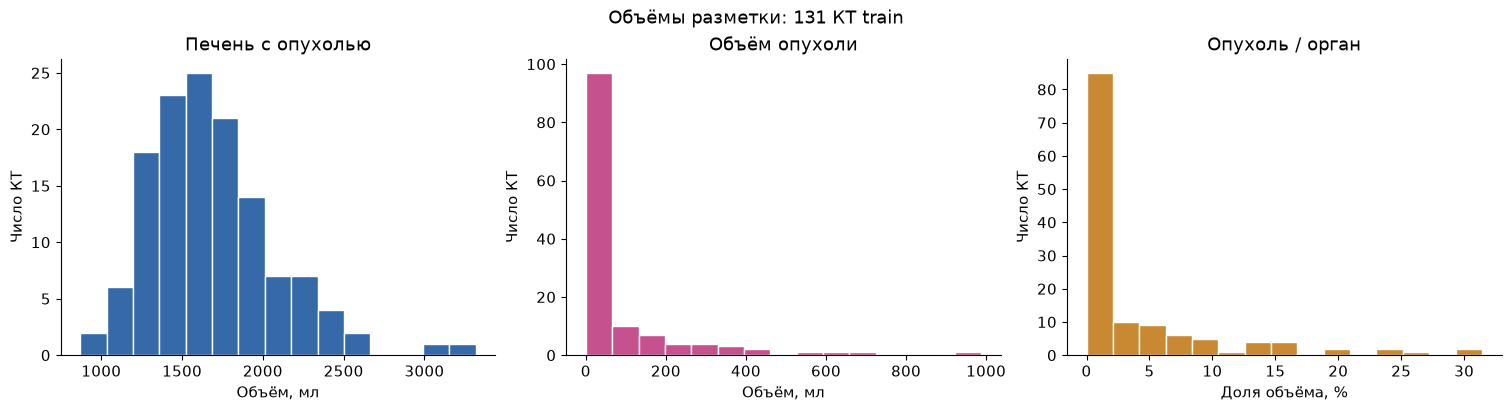

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), layout='constrained')
for ax, column, title, unit, color in zip(
    axes,
    ['organ_ml', 'tumor_ml', 'tumor_pct_organ'],
    ['Печень с опухолью', 'Объём опухоли', 'Опухоль / орган'],
    ['Объём, мл', 'Объём, мл', 'Доля объёма, %'],
    ['#3569A8', '#C5528E', '#C98932'],
):
    ax.hist(
        stats[column].dropna(), bins=min(15, max(3, len(stats) // 2)),
        color=color, edgecolor='white',
    )
    ax.set(title=title, xlabel=unit, ylabel='Число КТ')
fig.suptitle(f'Объёмы разметки: {len(stats)} КТ train')
plt.show()

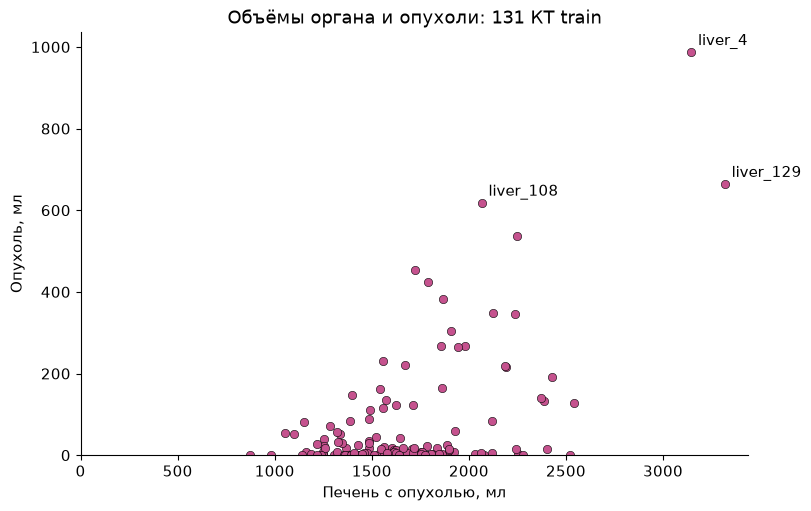

In [17]:
fig, ax = plt.subplots(figsize=(8, 5), layout='constrained')
ax.scatter(
    stats.organ_ml, stats.tumor_ml,
    color='#C5528E', edgecolors='black', linewidths=0.4,
)
for row in stats.nlargest(3, 'tumor_ml').itertuples():
    ax.annotate(
        row.case_id, (row.organ_ml, row.tumor_ml),
        xytext=(5, 5), textcoords='offset points',
    )
ax.set(
    title=f'Объёмы органа и опухоли: {len(stats)} КТ train',
    xlabel='Печень с опухолью, мл', ylabel='Опухоль, мл',
    xlim=(0, None), ylim=(0, None),
)
plt.show()

Пустых масок органа нет; в 13 КТ опухоль не размечена.
Медианная доля опухоли — 0,68% органа и 0,017% всей КТ: классы сильно несбалансированы.

## 4. Примеры КТ и разметки

Оставим четыре исследования из исходного анализа.
Аксиальный срез выберем по максимальной площади опухоли, а при её отсутствии — печени.
Две другие плоскости пройдут через точку внутри этой области.

In [18]:
CASE_IDS = ['liver_1', 'liver_4', 'liver_105', 'liver_104']
WINDOW_CENTER = 60
WINDOW_WIDTH = 160

unknown_ids = set(CASE_IDS) - set(train.case_id)
if unknown_ids:
    raise ValueError(f'Неизвестные исследования: {sorted(unknown_ids)}')
example_cases = train.set_index('case_id').loc[CASE_IDS].reset_index()

Для показа сохраним только три среза каждой КТ. Одновременно подготовим выборки HU:
сетка с шагом 4 × 4 × 2, до 50 000 конечных значений на класс и КТ.
Маленькая опухоль может не попасть в такую выборку; её наличие проверяется по полной маске.

In [19]:
examples = []
example_rows = []
hu_samples = []
hu_rows = []

for case in example_cases.itertuples():
    ct_image = nib.as_closest_canonical(load_image(case.image))
    mask_image = nib.as_closest_canonical(load_image(case.label))

    ct = np.asarray(ct_image.dataobj, dtype=np.float32)
    mask = np.asarray(mask_image.dataobj)
    spacing = ct_image.header.get_zooms()
    labels = np.unique(mask)

    has_tumor = 2 in labels

    region = mask == 2 if has_tumor else mask > 0
    z = int(region.sum(axis=(0, 1)).argmax()) if region.any() else ct.shape[2] // 2
    points = np.argwhere(region[:, :, z])
    x, y = (
        points[len(points) // 2]
        if len(points)
        else (ct.shape[0] // 2, ct.shape[1] // 2)
    )
    indices = (int(x), int(y), z)
    del region, points

    slices = []
    for axis, index in enumerate(indices):
        slices.append((
            np.take(ct, index, axis=axis).T,
            np.take(mask, index, axis=axis).T,
        ))
    examples.append({
        'case_id': case.case_id,
        'spacing': spacing,
        'indices': indices,
        'slices': slices,
        'has_tumor': has_tumor,
    })
    example_rows.append({
        'case_id': case.case_id,
        'shape_RAS': ct.shape,
        'spacing_mm': tuple(round(float(s), 3) for s in spacing),
        'tilt_deg': round(float(np.rad2deg(nib.affines.obliquity(ct_image.affine)).max()), 4),
        'tumor_in_mask': bool(has_tumor),
        'slices_xyz': tuple(indices),
    })

    ct_small = ct[::4, ::4, ::2]
    mask_small = mask[::4, ::4, ::2]
    rng = np.random.default_rng(SEED)  # выборка КТ не зависит от порядка остальных примеров
    for label, name in [(0, 'Background'), (1, 'Liver only'), (2, 'Tumor')]:
        values = ct_small[mask_small == label]
        values = values[np.isfinite(values)]
        if len(values) > 50_000:
            values = rng.choice(values, size=50_000, replace=False)
        hu_samples.append(pd.DataFrame({
            'case_id': case.case_id,
            'tissue': name,
            'hu': values,
        }))
        hu_rows.append({
            'case_id': case.case_id,
            'tissue': name,
            'sample_n': len(values),
            'min_HU': values.min() if len(values) else np.nan,
            'median_HU': np.median(values) if len(values) else np.nan,
            'max_HU': values.max() if len(values) else np.nan,
            'outside_plot_pct': (
                100 * ((values < -200) | (values > 300)).mean()
                if len(values) else np.nan
            ),
        })
    del ct, mask, ct_small, mask_small, ct_image, mask_image

example_info = pd.DataFrame(example_rows).set_index('case_id')
hu = pd.concat(hu_samples, ignore_index=True)
hu_summary = pd.DataFrame(hu_rows).set_index(['case_id', 'tissue'])

In [20]:
example_info

,shape_RAS,spacing_mm,tilt_deg,tumor_in_mask,slices_xyz
case_id,,,,,
liver_1,"(512, 512, 123)","(0.676, 0.676, 5.0)",0.0,True,"(323, 206, 58)"
liver_4,"(512, 512, 841)","(0.902, 0.902, 0.8)",0.0,True,"(368, 184, 463)"
liver_105,"(512, 512, 986)","(0.844, 0.844, 0.7)",0.0,False,"(337, 367, 574)"
liver_104,"(512, 512, 781)","(0.781, 0.781, 0.8)",0.0,True,"(326, 287, 355)"


### 4.1. Срезы с масками

In [21]:
def show_slice(ax, example, axis):
    image_slice, mask_slice = example['slices'][axis]
    spacing = example['spacing']
    other_axes = [i for i in range(3) if i != axis]
    extent = [
        0, image_slice.shape[1] * spacing[other_axes[0]],
        0, image_slice.shape[0] * spacing[other_axes[1]],
    ]
    ax.imshow(
        image_slice, cmap='gray', origin='lower', extent=extent,
        vmin=WINDOW_CENTER - WINDOW_WIDTH / 2,
        vmax=WINDOW_CENTER + WINDOW_WIDTH / 2,
    )
    for label, color, style in [(1, '#E5B44A', '-'), (2, '#C5528E', '--')]:
        region = np.ma.masked_where(mask_slice != label, mask_slice)
        ax.imshow(
            region, cmap=ListedColormap([color]), alpha=0.35,
            origin='lower', extent=extent, interpolation='nearest',
        )
        if (mask_slice == label).any() and (mask_slice != label).any():
            ax.contour(
                mask_slice == label, levels=[0.5], colors=[color],
                linestyles=style, linewidths=0.7, origin='lower', extent=extent,
            )
    plane, x_label, y_label = {
        0: ('Sagittal', 'P → A, mm', 'I → S, mm'),
        1: ('Coronal', 'L → R, mm', 'I → S, mm'),
        2: ('Axial', 'L → R, mm', 'P → A, mm'),
    }[axis]
    ax.set(
        title=f"{example['case_id']} | {plane}: {example['indices'][axis]}",
        xlabel=x_label, ylabel=y_label, aspect='equal',
    )

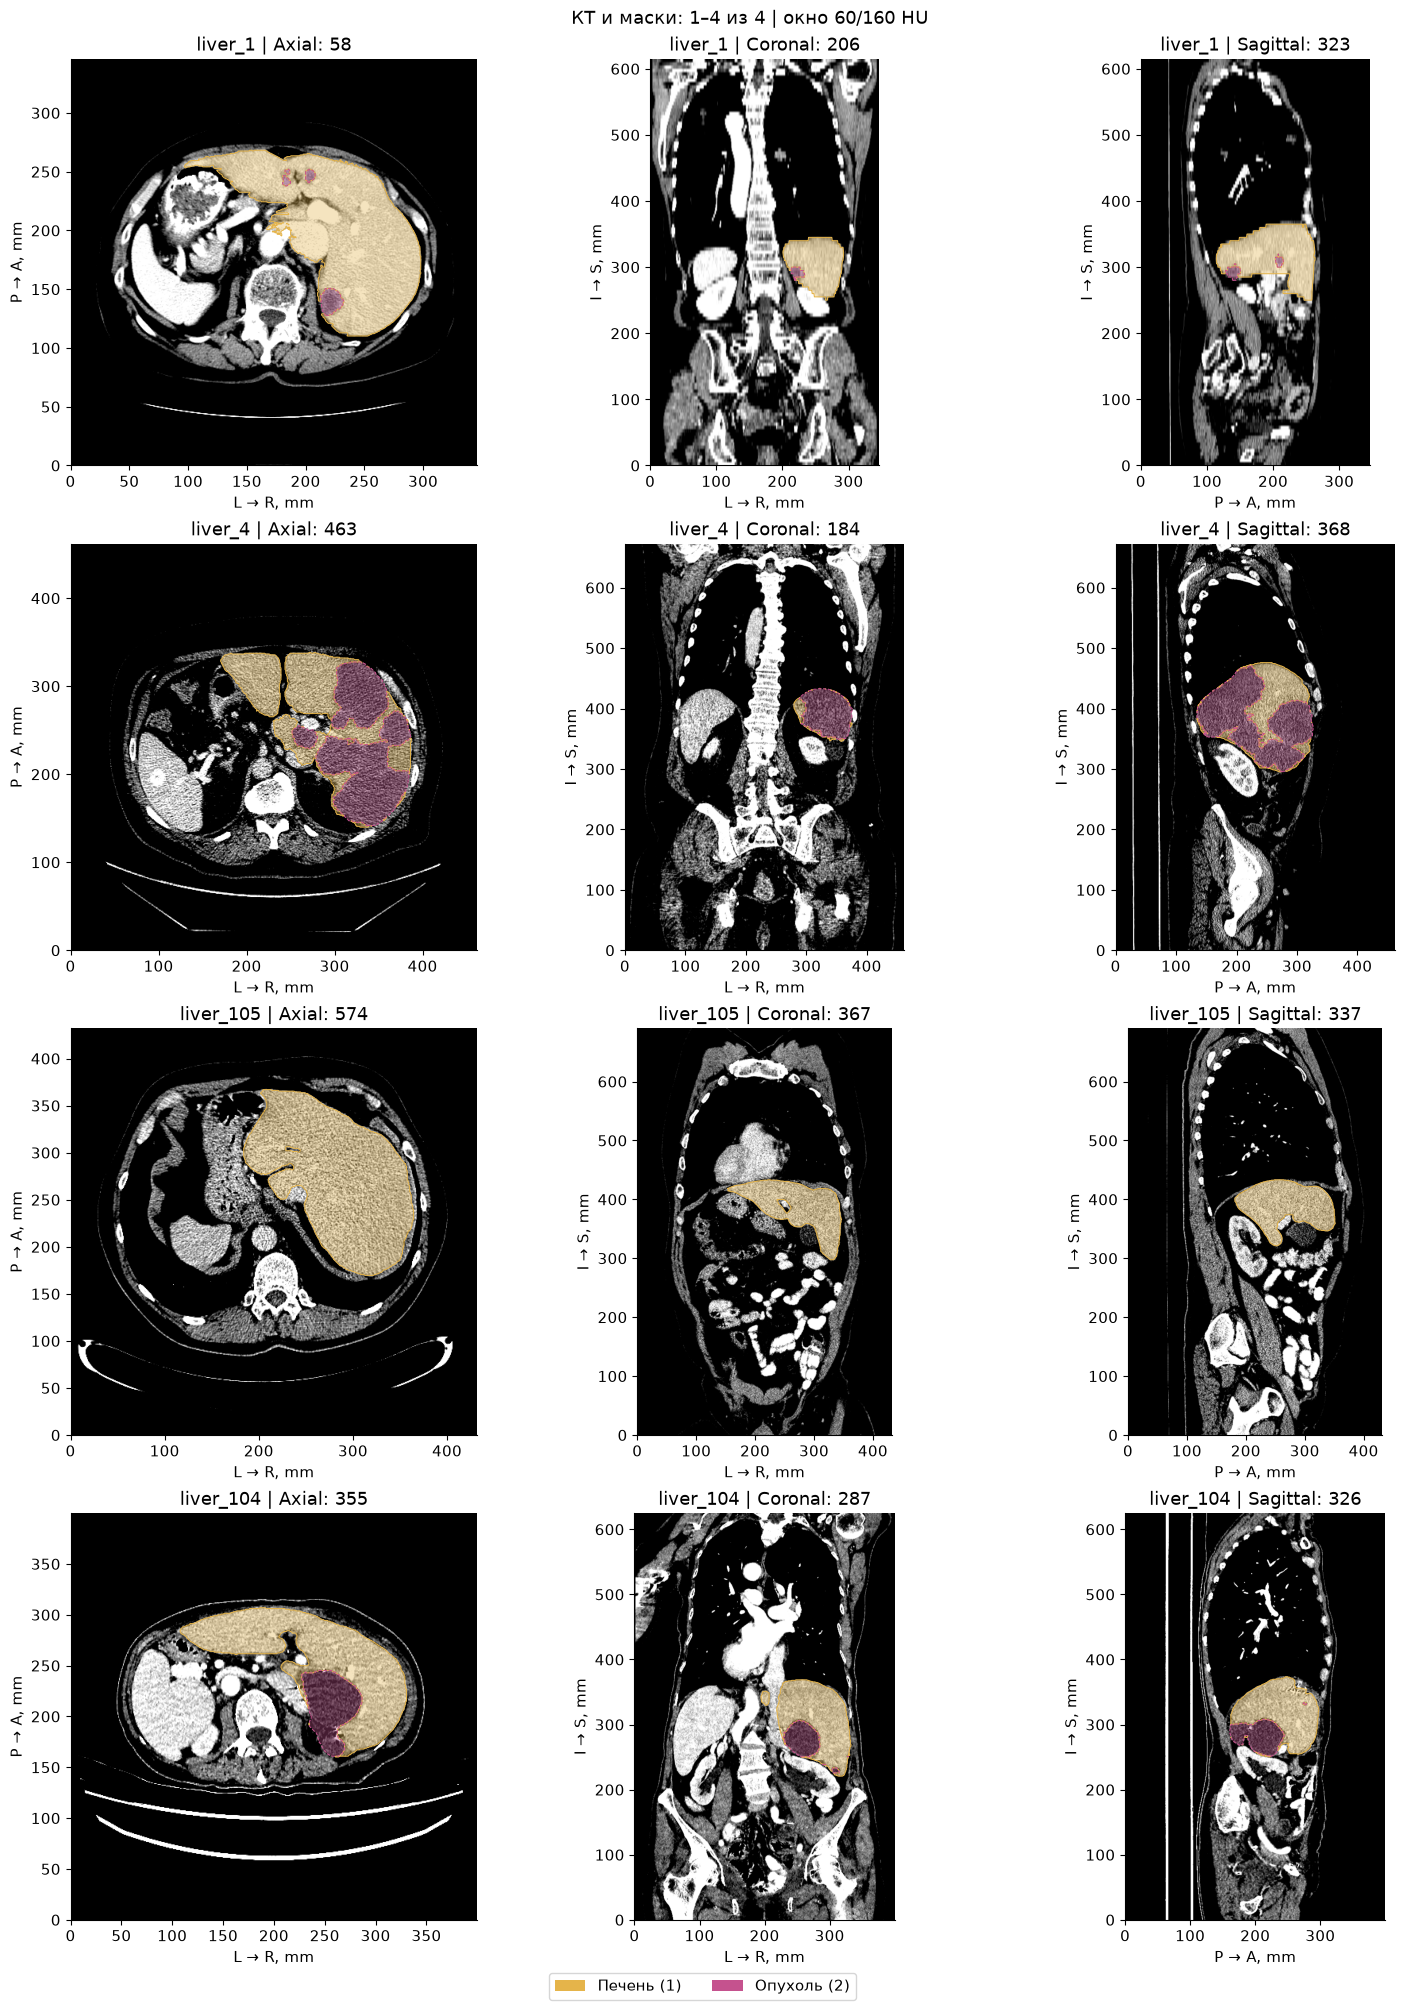

In [22]:
for start in range(0, len(examples), 4):
    batch = examples[start:start + 4]
    fig, axes = plt.subplots(
        len(batch), 3, figsize=(15, 5 * len(batch)),
        squeeze=False, layout='constrained',
    )
    for row, example in enumerate(batch):
        for ax, axis in zip(axes[row], [2, 1, 0]):
            show_slice(ax, example, axis)

    fig.suptitle(
        f'КТ и маски: {start + 1}–{start + len(batch)} из {len(examples)}'
        f' | окно {WINDOW_CENTER}/{WINDOW_WIDTH} HU'
    )
    fig.legend(
        handles=[
            Patch(facecolor='#E5B44A', label='Печень (1)'),
            Patch(facecolor='#C5528E', label='Опухоль (2)'),
        ],
        loc='outside lower center', ncols=2,
    )
    plt.show()
    plt.close(fig)

В выбранных КТ различаются размеры и расположение разметки.
Для liver_105 показана только печень: метки опухоли в этой маске нет.

### 4.2. HU выбранных исследований

Сравним распределения отдельно для каждой КТ и класса. Высота линии — доля выбранных
вокселей класса в интервале 5 HU; значения вне −200…300 HU остаются в знаменателе.
Фон включает воздух и все ткани с меткой 0. При sample_n = 0 статистики класса отсутствуют.

In [23]:
hu_summary.round(1)

sample_n  min_HU  median_HU  max_HU  outside_plot_pct
case_id   tissue                                                           
liver_1   Background     50000 -1024.0     -848.0  3071.0              58.7
          Liver only     20477   -81.0      115.0   269.0               0.0
          Tumor            230   -28.0       73.0   117.0               0.0
liver_4   Background     50000 -2048.0     -908.0  1825.0              62.8
          Liver only     50000  -376.0       80.0   235.0               0.1
          Tumor          47323  -247.0       29.0   206.0               0.0
liver_105 Background     50000 -1024.0     -882.0  1358.0              58.5
          Liver only     50000   -84.0       92.0   232.0               0.0
          Tumor              0     NaN        NaN     NaN               NaN
liver_104 Background     50000 -1024.0     -987.0  9911.0              74.3
          Liver only     50000  -484.0       98.0  3200.0               0.2
          Tumor           8606  -537.0        9.0  2816.0               0.3

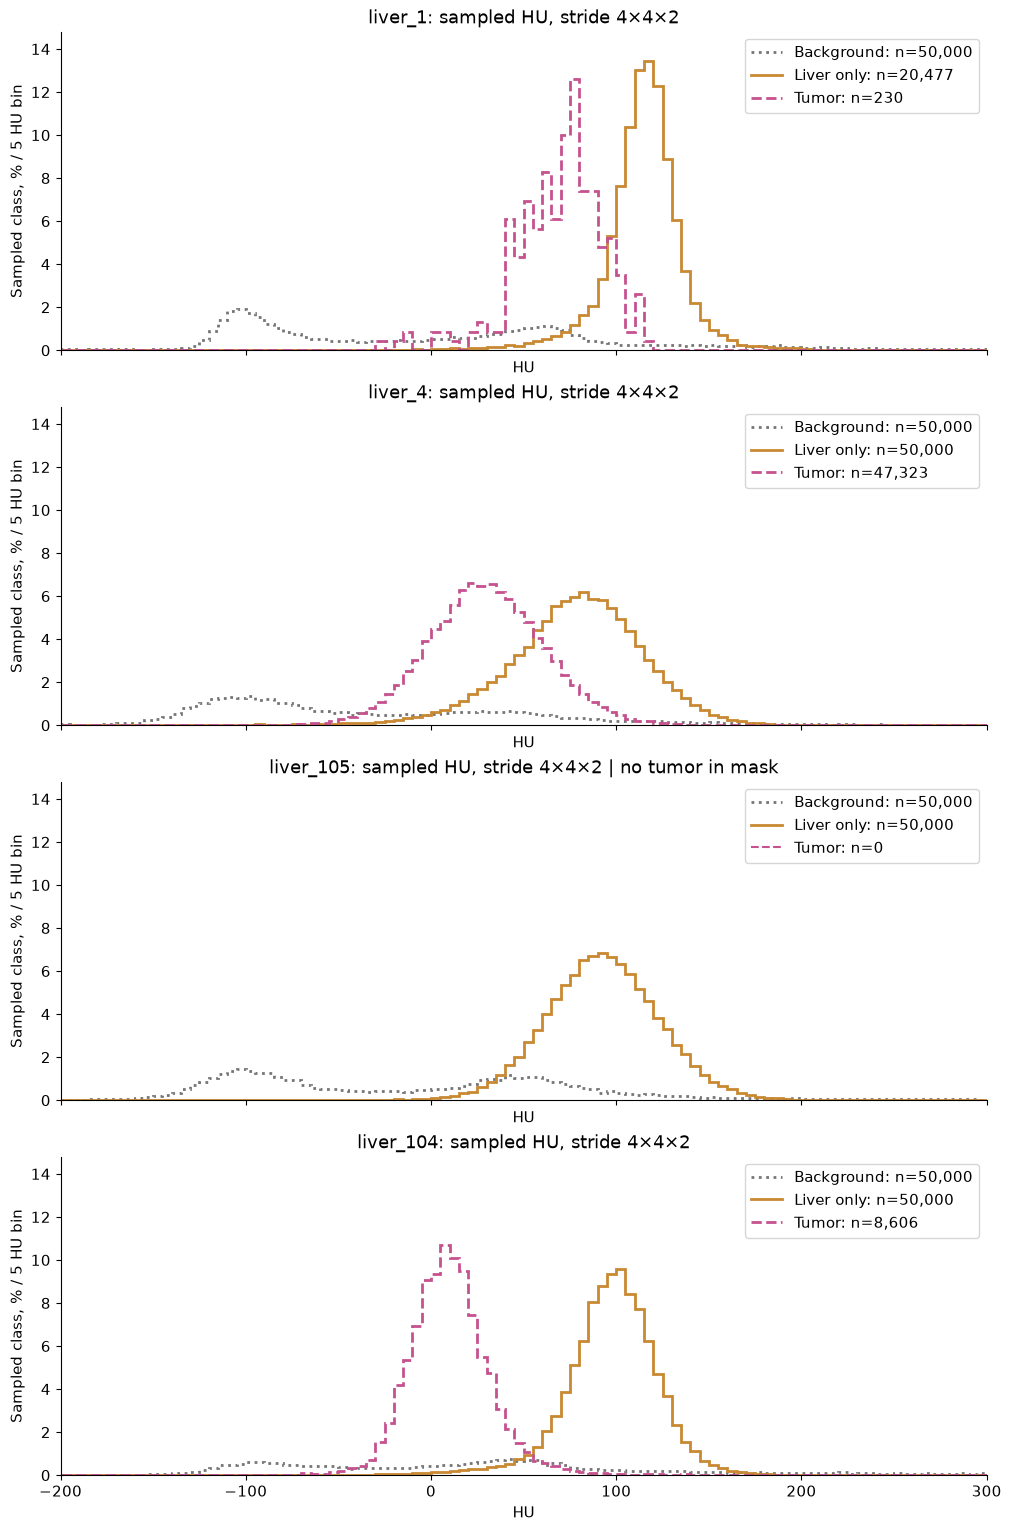

In [24]:
bins = np.linspace(-200, 300, 101)
max_bin_pct = 1.0
for _, group in hu.groupby(['case_id', 'tissue']):
    counts, _ = np.histogram(group.hu, bins=bins)
    max_bin_pct = max(max_bin_pct, 100 * counts.max() / len(group))

for start in range(0, len(examples), 4):
    batch = examples[start:start + 4]
    fig, axes = plt.subplots(
        len(batch), 1, figsize=(10, 3.8 * len(batch)),
        squeeze=False, sharex=True, sharey=True, layout='constrained',
    )
    for ax, example in zip(axes[:, 0], batch):
        case_id = example['case_id']
        case_hu = hu[hu.case_id == case_id]
        for name, color, style in [
            ('Background', '#757575', ':'),
            ('Liver only', '#C98932', '-'),
            ('Tumor', '#C5528E', '--'),
        ]:
            values = case_hu.loc[case_hu.tissue == name, 'hu']
            label = f'{name}: n={len(values):,}'
            if len(values):
                counts, edges = np.histogram(values, bins=bins)
                ax.stairs(
                    100 * counts / len(values), edges,
                    color=color, linestyle=style, linewidth=2, label=label,
                )
            else:
                ax.plot([], [], color=color, linestyle=style, label=label)
        note = '' if example['has_tumor'] else ' | no tumor in mask'
        ax.set(
            title=f'{case_id}: sampled HU, stride 4×4×2{note}',
            xlabel='HU', ylabel='Sampled class, % / 5 HU bin',
            xlim=(-200, 300), ylim=(0, 1.1 * max_bin_pct),
        )
        ax.legend()

    plt.show()
    plt.close(fig)

Распределения HU печени и опухоли перекрываются и различаются между КТ.
Эти примеры помогают увидеть различия, но для общего сравнения нужна вся размеченная выборка.

## 5. HU по всей размеченной выборке

Теперь используем все конечные HU печени (метка 1) и опухоли (метка 2) в 131 КТ,
без разреженной сетки. Сначала считаем статистики внутри исследования.
Для парного сравнения оставляем КТ с обоими классами; каждая КТ имеет одинаковый вес.

In [25]:
cohort_cases = headers[headers.split == 'train'].sort_values('case_id').copy()
assert len(cohort_cases) == metadata['numTraining'], 'В headers представлены не все обучающие КТ'
assert cohort_cases.case_id.is_unique, 'В headers есть повторяющиеся исследования'

COHORT_BINS = np.arange(-200, 305, 5)
cohort_rows = []
cohort_histograms = {'Liver only': {}, 'Tumor': {}}

for cohort_case in tqdm(
    cohort_cases.itertuples(), total=len(cohort_cases), desc='HU по всем КТ'
):
    cohort_ct_image = load_image(cohort_case.image)
    cohort_mask_image = load_image(cohort_case.label)
    cohort_ct = np.asarray(cohort_ct_image.dataobj, dtype=np.float32)
    cohort_mask = np.asarray(cohort_mask_image.dataobj)

    for cohort_label, cohort_name in [(1, 'Liver only'), (2, 'Tumor')]:
        cohort_values = cohort_ct[cohort_mask == cohort_label]
        cohort_total = len(cohort_values)
        cohort_values = cohort_values[np.isfinite(cohort_values)]
        cohort_finite = len(cohort_values)

        if cohort_finite:
            q05, q25, median, q75, q95 = np.percentile(cohort_values, [5, 25, 50, 75, 95])
            cohort_counts, _ = np.histogram(cohort_values, bins=COHORT_BINS)
            cohort_histograms[cohort_name][cohort_case.case_id] = (
                100 * cohort_counts / cohort_finite
            )
            cohort_outside_pct = 100 * ((cohort_values < -200) | (cohort_values > 300)).mean()
        else:
            q05 = q25 = median = q75 = q95 = np.nan
            cohort_outside_pct = np.nan

        cohort_rows.append({
            'case_id': cohort_case.case_id,
            'tissue': cohort_name,
            'n_voxels': cohort_total,
            'n_finite': cohort_finite,
            'n_nonfinite': cohort_total - cohort_finite,
            'p05_hu': q05,
            'p25_hu': q25,
            'median_hu': median,
            'p75_hu': q75,
            'p95_hu': q95,
            'outside_plot_pct': cohort_outside_pct,
        })
    del cohort_ct, cohort_mask, cohort_ct_image, cohort_mask_image, cohort_values

cohort_stats = pd.DataFrame(cohort_rows).set_index(['case_id', 'tissue'])
cohort_liver = cohort_stats.xs('Liver only', level='tissue')
cohort_tumor = cohort_stats.xs('Tumor', level='tissue')
cohort_pairs = pd.DataFrame({
    'liver_median_hu': cohort_liver.median_hu,
    'tumor_median_hu': cohort_tumor.median_hu,
}).dropna()
cohort_pairs['delta_hu'] = cohort_pairs.tumor_median_hu - cohort_pairs.liver_median_hu

HU по всем КТ: 100%|██████████| 131/131 [06:14<00:00,  2.86s/it]


In [26]:
cohort_coverage = pd.Series({
    'Прочитано КТ': len(cohort_cases),
    'КТ для парного сравнения': len(cohort_pairs),
    'КТ без метки опухоли': int((cohort_tumor.n_voxels == 0).sum()),
    'Классов в КТ с неконечными HU': int((cohort_stats.n_nonfinite > 0).sum()),
    'Классов с разметкой, но без конечных HU': int(
        ((cohort_stats.n_voxels > 0) & (cohort_stats.n_finite == 0)).sum()
    ),
}, name='Количество')
cohort_coverage.to_frame()

,Количество
Прочитано КТ,131
КТ для парного сравнения,118
КТ без метки опухоли,13
Классов в КТ с неконечными HU,0
"Классов с разметкой, но без конечных HU",0


### 5.1. Медианы и распределения

В таблице — квартили медиан по исследованиям.
Разность считаем внутри одной КТ, медиана опухоли минус медиана печени.
На графике усредняем нормированные гистограммы тех же парных КТ.

In [27]:
if cohort_pairs.empty:
    raise ValueError('Нет КТ с конечными HU обоих классов. Проверьте таблицу покрытия выше.')

print(f'Парное сравнение: {len(cohort_pairs)} из {len(cohort_cases)} КТ')
cohort_pairs.rename(columns={
    'liver_median_hu': 'Медиана HU печени',
    'tumor_median_hu': 'Медиана HU опухоли',
    'delta_hu': 'Разность медиан, HU',
}).quantile([0.25, 0.5, 0.75]).rename(index={
    0.25: '25-й процентиль', 0.5: 'Медиана по КТ', 0.75: '75-й процентиль',
}).round(1)

Парное сравнение: 118 из 131 КТ


,Медиана HU печени,Медиана HU опухоли,"Разность медиан, HU"
25-й процентиль,90.8,49.2,-48.8
Медиана по КТ,99.5,67.0,-34.5
75-й процентиль,114.0,78.8,-22.2


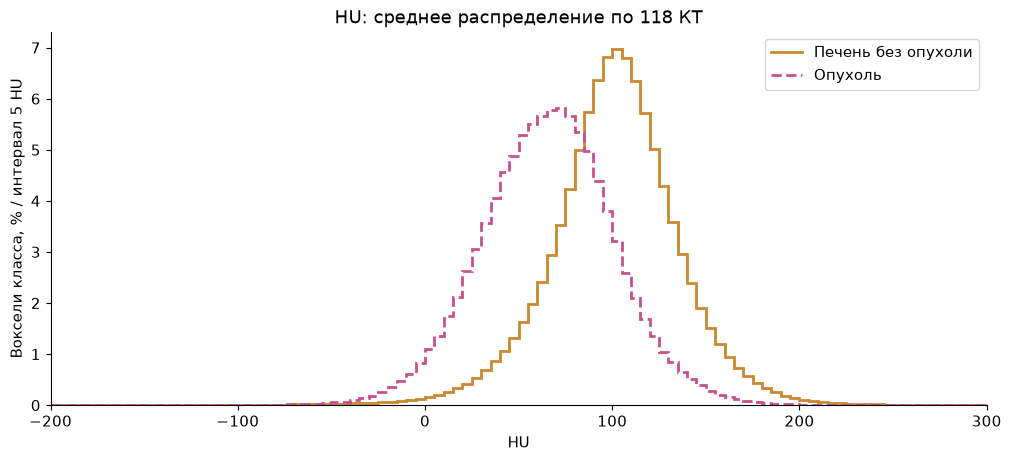

In [28]:
cohort_mean_hist = {}
cohort_outside = {}
for cohort_name in ['Liver only', 'Tumor']:
    cohort_mean_hist[cohort_name] = np.stack([
        cohort_histograms[cohort_name][case_id] for case_id in cohort_pairs.index
    ]).mean(axis=0)
    cohort_outside[cohort_name] = cohort_stats.xs(cohort_name, level='tissue').loc[
        cohort_pairs.index, 'outside_plot_pct'
    ].mean()

fig, ax = plt.subplots(figsize=(10, 4.5), layout='constrained')
for name, title, color, style in [
    ('Liver only', 'Печень без опухоли', '#C98932', '-'),
    ('Tumor', 'Опухоль', '#C5528E', '--'),
]:
    ax.stairs(
        cohort_mean_hist[name], COHORT_BINS,
        color=color, linestyle=style, linewidth=2, label=title,
    )
ax.set(
    title=f'HU: среднее распределение по {len(cohort_pairs)} КТ',
    xlabel='HU', ylabel='Воксели класса, % / интервал 5 HU',
    xlim=(-200, 300), ylim=(0, None),
)
ax.legend()
plt.show()
plt.close(fig)

In [29]:
pd.Series(cohort_outside, name='Средняя доля вне −200…300 HU, %').round(3).to_frame()

,"Средняя доля вне −200…300 HU, %"
Liver only,0.024
Tumor,0.021


Медиана парной разности — −34,5 HU:
опухоль обычно менее интенсивна, но перекрытие распределений не даёт разделить ткани одним порогом.

## 6. Сравнение двух вариантов ресэмплинга

Сравним **0,8 × 0,8 × 1** и **0,7 × 0,7 × 1 мм** на всех масках train.
Оба варианта получаем непосредственно из оригинала с учётом поправок геометрии.
Сохраняем направления осей и полный физический охват; размеры округляем вверх,
совмещая начальные границы вокселей. У противоположной границы возможен неполный воксель.

Маски переносим ближайшим соседом, КТ — линейной интерполяцией без сглаживания.
За пределами исходной сетки используем 0 для масок и −1024 HU для КТ.
Более плотная сетка увеличивает число вокселей, но не восстанавливает отсутствующие детали.

In [44]:
TARGET_SPACINGS = {
    0.8: np.array([0.8, 0.8, 1.0]),
    0.7: np.array([0.7, 0.7, 1.0]),
}
RESAMPLE_STYLES = {0.8: ('#3569AD', '-'), 0.7: ('#C98932', '--')}
RESAMPLE_EXAMPLE_IDS = []
HU_MAX_VOXELS = 50_000
RESAMPLE_WINDOW = (-20, 140)
ERROR_MAX_HU = 50

resampling_cases = train.sort_values('case_id').copy()
assert len(resampling_cases) == metadata['numTraining'], 'В train должны быть все размеченные КТ'
assert resampling_cases.case_id.is_unique

### 6.1. Как изменится шаг

In [31]:
spacing_rows = []
for step_xy, target_spacing in TARGET_SPACINGS.items():
    for axis, target in zip(['x', 'y', 'z'], target_spacing):
        old = resampling_cases[f's{axis}_mm']
        equal = np.isclose(old, target, rtol=0, atol=1e-6)
        spacing_rows.append({
            'Шаг x/y, мм': step_xy,
            'Ось': axis,
            'Новый шаг, мм': target,
            'КТ: шаг крупнее': int(((old < target) & ~equal).sum()),
            'КТ: шаг мельче': int(((old > target) & ~equal).sum()),
            'КТ: шаг прежний': int(equal.sum()),
        })
pd.DataFrame(spacing_rows).set_index(['Ось', 'Шаг x/y, мм']).sort_index(
    level=[0, 1], ascending=[True, False],
)

Новый шаг, мм  КТ: шаг крупнее  КТ: шаг мельче  \
Ось Шаг x/y, мм                                                   
x   0.8                    0.8              103              28   
    0.7                    0.7               37              94   
y   0.8                    0.8              103              28   
    0.7                    0.7               37              94   
z   0.8                    1.0               51              66   
    0.7                    1.0               51              66   

                 КТ: шаг прежний  
Ось Шаг x/y, мм                   
x   0.8                        0  
    0.7                        0  
y   0.8                        0  
    0.7                        0  
z   0.8                       14  
    0.7                       14

Шаг 0,8 мм укрупняет сетку по x/y в 103 КТ, шаг 0,7 мм — в 37.
Изменение шага по z одинаково в обоих вариантах.

### 6.2. Сетка и перенос меток

ratio — отношение нового шага к исходному. Для ближайшего соседа на границе
двух центров выбираем больший индекс; то же правило применяется к ID компонентов.
Для КТ affine_transform
получает отображение из новой сетки в исходную.

In [32]:
def resampling_grid(image, target_spacing):
    spacing = np.linalg.norm(image.affine[:3, :3], axis=0)
    ratio = np.asarray(target_spacing) / spacing
    shape = np.maximum(1, np.ceil(np.array(image.shape) / ratio - 1e-4).astype(int))
    affine = image.affine.copy()
    affine[:3, :3] = image.affine[:3, :3] @ np.diag(ratio)
    affine[:3, 3] += 0.5 * (affine[:3, :3] - image.affine[:3, :3]).sum(axis=1)
    return tuple(shape), ratio, affine


def nearest_indices(shape, ratio):
    return [
        np.floor((np.arange(n) + 0.5) * step).astype(int)
        for n, step in zip(shape, ratio)
    ]


def resample_labels(array, indices):
    clipped = [
        values.clip(0, array.shape[axis] - 1)
        for axis, values in enumerate(indices)
    ]
    result = array[np.ix_(*clipped)]
    for axis, values in enumerate(indices):
        outside = [slice(None)] * 3
        outside[axis] = (values < 0) | (values >= array.shape[axis])
        result[tuple(outside)] = 0
    return result

### 6.3. Исходные опухолевые компоненты

Выделяем компоненты с 26-связностью и проверяем, остался ли хотя бы один воксель
каждого исходного ID на новой сетке. Это позволяет заметить исчезновение мелких объектов.

In [33]:
def component_loss_records(mask, indices_by_step, voxel_ml):
    """Один набор исходных ID, проверяем его присутствие на обеих новых сетках."""
    tumor = mask == 2
    if not tumor.any():
        return []
    occupied = [
        np.flatnonzero(tumor.any(axis=tuple(j for j in range(3) if j != axis)))
        for axis in range(3)
    ]
    starts = [int(values[0]) for values in occupied]
    stops = [int(values[-1]) + 1 for values in occupied]
    box = tuple(slice(start, stop) for start, stop in zip(starts, stops))
    components, n_components = ndi.label(tumor[box], structure=np.ones((3, 3, 3)))
    del tumor
    counts = np.bincount(components.ravel(), minlength=n_components + 1)

    rows = []
    for step_xy, indices in indices_by_step.items():
        selected = [
            np.unique(values[(values >= start) & (values < stop)] - start)
            for values, start, stop in zip(indices, starts, stops)
        ]
        present = np.zeros(n_components + 1, dtype=bool)
        if all(len(values) for values in selected):
            for z in range(0, len(selected[2]), 32):
                sampled = components[np.ix_(selected[0], selected[1], selected[2][z:z + 32])]
                present[np.unique(sampled)] = True
        rows.extend({
            'step_xy_mm': step_xy,
            'component_id': component,
            'original_voxels': int(counts[component]),
            'original_ml': float(counts[component] * voxel_ml),
            'lost': not bool(present[component]),
        } for component in range(1, n_components + 1))
    return rows

### 6.4. Расчёт по всем маскам

Объёмы сравниваем на исходной и новой сетках, Dice — после переноса туда и обратно.
Печень здесь включает опухоль. Для исходно отсутствующей опухоли относительное
изменение объёма и Dice оставляем пустыми. КТ на этом этапе не загружаем.

In [34]:
resample_rows = []
component_rows = []
grid_rows = []

for case in tqdm(
    resampling_cases.itertuples(),
    total=len(resampling_cases), desc='Маски: 0.8 и 0.7 мм',
):
    image = nib.as_closest_canonical(load_image(case.label))
    mask = np.asarray(image.dataobj)
    assert np.isin(mask, [0, 1, 2]).all(), f'{case.case_id}: неизвестные метки'
    mask = mask.astype(np.uint8, copy=False)
    voxel_before_ml = abs(np.linalg.det(image.affine[:3, :3])) / 1000
    indices_by_step = {}

    for step_xy, target_spacing in TARGET_SPACINGS.items():
        new_shape, ratio, new_affine = resampling_grid(image, target_spacing)
        forward_indices = nearest_indices(new_shape, ratio)
        indices_by_step[step_xy] = forward_indices
        mask_new = resample_labels(mask, forward_indices)
        mask_back = resample_labels(mask_new, nearest_indices(mask.shape, 1 / ratio))
        voxel_after_ml = abs(np.linalg.det(new_affine[:3, :3])) / 1000
        grid_rows.append({
            'case_id': case.case_id,
            'step_xy_mm': step_xy,
            'shape_before': mask.shape,
            'shape_after': new_shape,
            'spacing_before_mm': tuple(np.linalg.norm(image.affine[:3, :3], axis=0).round(6)),
            'voxel_count_ratio': np.prod(new_shape) / mask.size,
        })

        for name, label in [('Печень с опухолью', None), ('Опухоль', 2)]:
            original_mask = mask > 0 if label is None else mask == label
            converted = mask_new > 0 if label is None else mask_new == label
            restored = mask_back > 0 if label is None else mask_back == label
            n_before, n_after, n_back = (
                original_mask.sum(), converted.sum(), restored.sum()
            )
            before_ml, after_ml = n_before * voxel_before_ml, n_after * voxel_after_ml
            dice = (
                2 * np.count_nonzero(original_mask & restored) / (n_before + n_back)
                if n_before else np.nan
            )
            delta_pct = 100 * (after_ml / before_ml - 1) if n_before else np.nan
            resample_rows.append({
                'case_id': case.case_id,
                'step_xy_mm': step_xy,
                'tissue': name,
                'before_ml': before_ml,
                'after_ml': after_ml,
                'delta_ml': after_ml - before_ml,
                'delta_pct': delta_pct,
                'abs_delta_pct': abs(delta_pct),
                'dice_roundtrip': dice,
            })
            del original_mask, converted, restored
        del mask_new, mask_back

    for record in component_loss_records(mask, indices_by_step, voxel_before_ml):
        component_rows.append({'case_id': case.case_id, **record})
    del mask, image

resample_stats = pd.DataFrame(resample_rows)
assert not resample_stats.duplicated(['case_id', 'tissue', 'step_xy_mm']).any()
assert resample_stats.groupby(['case_id', 'tissue']).size().eq(2).all()
resample_geometry = pd.DataFrame(grid_rows).set_index(['case_id', 'step_xy_mm'])
resample_components = pd.DataFrame(component_rows, columns=[
    'case_id', 'step_xy_mm', 'component_id', 'original_voxels', 'original_ml', 'lost',
])

Маски: 0.8 и 0.7 мм: 100%|██████████| 131/131 [23:11<00:00, 10.62s/it]


### 6.5. Изменение объёмов и Dice

In [35]:
resample_stats.groupby(['tissue', 'step_xy_mm']).agg(**{
    'КТ с исходной разметкой': ('dice_roundtrip', 'count'),
    'Медиана Δ объёма, %': ('delta_pct', 'median'),
    '95-й процентиль |Δ объёма|, %': ('abs_delta_pct', lambda values: values.quantile(0.95)),
    'Медиана Dice туда-обратно': ('dice_roundtrip', 'median'),
    'Минимальный Dice туда-обратно': ('dice_roundtrip', 'min'),
}).sort_index(level=[0, 1], ascending=[True, False]).rename_axis(['Ткань', 'Шаг x/y, мм']).round(3)

КТ с исходной разметкой  Медиана Δ объёма, %  \
Ткань             Шаг x/y, мм                                                 
Опухоль           0.8                              118               -0.007   
                  0.7                              118                0.007   
Печень с опухолью 0.8                              131                0.000   
                  0.7                              131                0.001   

                               95-й процентиль |Δ объёма|, %  \
Ткань             Шаг x/y, мм                                  
Опухоль           0.8                                  3.536   
                  0.7                                  5.013   
Печень с опухолью 0.8                                  0.130   
                  0.7                                  0.150   

                               Медиана Dice туда-обратно  \
Ткань             Шаг x/y, мм                              
Опухоль           0.8                              0.987   
                  0.7                              0.997   
Печень с опухолью 0.8                              0.997   
                  0.7                              0.999   

                               Минимальный Dice туда-обратно  
Ткань             Шаг x/y, мм                                 
Опухоль           0.8                                  0.658  
                  0.7                                  0.667  
Печень с опухолью 0.8                                  0.993  
                  0.7                                  0.995

Медианный Dice опухоли выше при 0,7 мм: 0,997 против 0,987.
При этом 95-й процентиль абсолютного изменения её объёма выше: 5,01% против 3,54%.
Улучшение одной метрики не означает улучшения всех.

### 6.6. Парное сравнение

Сравним каждую КТ с ней же: для ΔDice = Dice₀․₇ − Dice₀․₈ лучше положительное значение,
для Δ абсолютной ошибки объёма — отрицательное.

In [37]:
paired_metrics = resample_stats.pivot(
    index=['case_id', 'tissue'], columns='step_xy_mm',
    values=['dice_roundtrip', 'abs_delta_pct'],
)
paired_changes = pd.DataFrame({
    'delta_dice': (
        paired_metrics['dice_roundtrip'][0.7] - paired_metrics['dice_roundtrip'][0.8]
    ),
    'delta_abs_volume_error_pct': (
        paired_metrics['abs_delta_pct'][0.7] - paired_metrics['abs_delta_pct'][0.8]
    ),
}).dropna()
paired_changes.groupby('tissue').agg(**{
    'КТ для сравнения': ('delta_dice', 'count'),
    'Dice выше при 0.7, КТ': ('delta_dice', lambda x: (x > 1e-6).sum()),
    'Dice одинаковый, КТ': ('delta_dice', lambda x: (x.abs() <= 1e-6).sum()),
    'Dice ниже при 0.7, КТ': ('delta_dice', lambda x: (x < -1e-6).sum()),
    'Медиана ΔDice (0.7 − 0.8)': ('delta_dice', 'median'),
    'Медиана Δ|ошибки объёма|, п.п.': ('delta_abs_volume_error_pct', 'median'),
}).round(4)

,КТ для сравнения,"Dice выше при 0.7, КТ","Dice одинаковый, КТ","Dice ниже при 0.7, КТ",Медиана ΔDice (0.7 − 0.8),"Медиана Δ|ошибки объёма|, п.п."
tissue,,,,,,
Опухоль,118,92,26,0,0.0057,-0.0312
Печень с опухолью,131,103,28,0,0.0013,-0.0001


При 0,7 мм Dice опухоли выше в 92 из 118 КТ, в остальных 26 он совпадает
с точностью до 10⁻⁶. Для печени с опухолью соотношение — 103 и 28 КТ.

### 6.7. Исчезнувшие компоненты

Посчитаем исчезновения и их исходный объём, затем разделим компоненты по размеру.
Частичные изменения сохранившихся компонентов отражены в объёмах и Dice выше.

In [38]:
if resample_components.empty:
    raise ValueError('В исходных масках не найдено опухолевых компонентов')

component_totals = []
for step_xy, group in resample_components.groupby('step_xy_mm', sort=False):
    lost = group[group.lost]
    component_totals.append({
        'Шаг x/y, мм': step_xy,
        'Исходных компонентов': len(group),
        'Исчезло': len(lost),
        'Исчезло, %': 100 * len(lost) / len(group),
        'КТ с исчезновениями': lost.case_id.nunique(),
        'Исходный объём исчезнувших, мл': lost.original_ml.sum(),
        'Доля исходного опухолевого объёма, %': (
            100 * lost.original_ml.sum() / group.original_ml.sum()
        ),
    })

lost_pairs = resample_components.pivot(
    index=['case_id', 'component_id'], columns='step_xy_mm', values='lost',
)
assert lost_pairs.notna().all().all(), 'Компоненты должны быть проверены на обеих сетках'
print(f'Исчезают только при 0.8 мм: {(lost_pairs[0.8] & ~lost_pairs[0.7]).sum()}')
print(f'Исчезают только при 0.7 мм: {(lost_pairs[0.7] & ~lost_pairs[0.8]).sum()}')
print(f'Исчезают при обоих шагах: {(lost_pairs[0.8] & lost_pairs[0.7]).sum()}')
pd.DataFrame(component_totals).set_index('Шаг x/y, мм').round(3)

Исчезают только при 0.8 мм: 1
Исчезают только при 0.7 мм: 0
Исчезают при обоих шагах: 11


,Исходных компонентов,Исчезло,"Исчезло, %",КТ с исчезновениями,"Исходный объём исчезнувших, мл","Доля исходного опухолевого объёма, %"
"Шаг x/y, мм",,,,,,
0.8,908,12,1.322,7,0.053,0.001
0.7,908,11,1.211,6,0.052,0.001


In [39]:
resample_components['size_group'] = pd.cut(
    resample_components.original_ml, bins=[0, 0.1, 1, np.inf],
    labels=['< 0,1 мл', '0,1–1 мл', '≥ 1 мл'], right=False,
)
component_summary = resample_components.groupby(
    ['size_group', 'step_xy_mm'], observed=False,
).agg(**{
    'Исходных компонентов': ('component_id', 'count'),
    'Исчезло': ('lost', 'sum'),
})
component_summary['Исчезло, %'] = (
    100 * component_summary['Исчезло'] / component_summary['Исходных компонентов']
)
component_summary.sort_index(level=[0, 1], ascending=[True, False]).rename_axis(
    ['Исходный объём компонента', 'Шаг x/y, мм'],
).round(2)

Исходных компонентов  Исчезло  \
Исходный объём компонента Шаг x/y, мм                                  
< 0,1 мл                  0.8                           153       12   
                          0.7                           153       11   
0,1–1 мл                  0.8                           406        0   
                          0.7                           406        0   
≥ 1 мл                    0.8                           349        0   
                          0.7                           349        0   

                                       Исчезло, %  
Исходный объём компонента Шаг x/y, мм              
< 0,1 мл                  0.8                7.84  
                          0.7                7.19  
0,1–1 мл                  0.8                0.00  
                          0.7                0.00  
≥ 1 мл                    0.8                0.00  
                          0.7                0.00

Из 908 исходных компонентов исчезают 12 при 0,8 мм и 11 при 0,7 мм.
Все они меньше 0,1 мл; малое изменение общего объёма может скрывать потерю мелких объектов.

### 6.8. Разбор двух примеров

Возьмём худшую КТ и КТ из середины рейтинга по меньшему из двух опухолевых Dice.
Выбор одинаков для обоих шагов

In [40]:
tumor_ranking = (
    resample_stats[resample_stats.tissue.eq('Опухоль')]
    .groupby('case_id').dice_roundtrip.min()
)
tumor_ranking = tumor_ranking.dropna().sort_values(kind='stable')
if tumor_ranking.empty:
    raise ValueError('Нет КТ с опухолью для выбора примеров')
if RESAMPLE_EXAMPLE_IDS:
    resample_example_ids = list(dict.fromkeys(RESAMPLE_EXAMPLE_IDS))
else:
    resample_example_ids = list(dict.fromkeys([
        tumor_ranking.index[0],
        tumor_ranking.index[len(tumor_ranking) // 2],
    ]))
assert set(resample_example_ids) <= set(resampling_cases.case_id), 'Неизвестный case_id'

resample_stats[resample_stats.case_id.isin(resample_example_ids)].merge(
    resample_geometry.reset_index(), on=['case_id', 'step_xy_mm'], validate='many_to_one',
)[[
    'case_id', 'tissue', 'step_xy_mm', 'shape_before', 'shape_after',
    'before_ml', 'after_ml', 'delta_pct', 'dice_roundtrip',
]].sort_values(
    ['case_id', 'tissue', 'step_xy_mm'], ascending=[True, True, False],
).round(3)

,case_id,tissue,step_xy_mm,shape_before,shape_after,before_ml,after_ml,delta_pct,dice_roundtrip
1,liver_122,Опухоль,0.8,"(512, 512, 422)","(442, 442, 633)",56.901,57.191,0.510,0.987
3,liver_122,Опухоль,0.7,"(512, 512, 422)","(505, 505, 633)",56.901,56.732,-0.297,0.998
0,liver_122,Печень с опухолью,0.8,"(512, 512, 422)","(442, 442, 633)",1322.781,1322.374,-0.031,0.997
2,liver_122,Печень с опухолью,0.7,"(512, 512, 422)","(505, 505, 633)",1322.781,1321.225,-0.118,1.000
5,liver_127,Опухоль,0.8,"(512, 512, 987)","(494, 494, 691)",0.124,0.064,-48.452,0.658
7,liver_127,Опухоль,0.7,"(512, 512, 987)","(565, 565, 691)",0.124,0.067,-45.931,0.667
4,liver_127,Печень с опухолью,0.8,"(512, 512, 987)","(494, 494, 691)",1631.290,1631.300,0.001,0.996
6,liver_127,Печень с опухолью,0.7,"(512, 512, 987)","(565, 565, 691)",1631.290,1631.243,-0.003,0.996


Сравним HU после цикла туда-обратно на одинаковых исходных точках:
до 50 000 вокселей каждой ткани, с общим отступом от границ и проверкой конечных значений.
В HU-таблице печень — метка 1. Срез, физическая область и окно показа одинаковы.
Карты ошибки включают края К

In [41]:
resample_examples = []
resample_hu_rows = []

for case_id in tqdm(resample_example_ids, desc='Примеры: 0.8 и 0.7 мм'):
    case = resampling_cases.set_index('case_id').loc[case_id]
    ct_image = nib.as_closest_canonical(load_image(case.image))
    mask_image = nib.as_closest_canonical(load_image(case.label))
    assert ct_image.shape == mask_image.shape and np.allclose(
        ct_image.affine, mask_image.affine, rtol=0, atol=1e-4
    )
    ct = np.asarray(ct_image.dataobj, dtype=np.float32)
    mask = np.asarray(mask_image.dataobj)
    assert np.isin(mask, [0, 1, 2]).all(), f'{case_id}: неизвестные метки'
    mask = mask.astype(np.uint8, copy=False)
    spacing = np.linalg.norm(ct_image.affine[:3, :3], axis=0)
    grids = {
        step: resampling_grid(ct_image, target)
        for step, target in TARGET_SPACINGS.items()
    }

    # Общие исходные точки и общий отступ от границ для обеих сеток.
    max_ratio = np.max([grid[1] for grid in grids.values()], axis=0)
    margin = 2 * np.maximum(1, max_ratio)[:, None]
    hu_reference = {}
    rng = np.random.default_rng(SEED)
    for label, name in [(1, 'Печень без опухоли'), (2, 'Опухоль')]:
        flat_indices = np.flatnonzero(mask == label)
        if len(flat_indices) > HU_MAX_VOXELS:
            flat_indices = rng.choice(flat_indices, HU_MAX_VOXELS, replace=False)
        points = np.array(np.unravel_index(flat_indices, mask.shape))
        inside = (
            (points >= margin)
            & (points <= np.array(mask.shape)[:, None] - 1 - margin)
        ).all(axis=0)
        points = points[:, inside]
        hu_reference[name] = {'points': points, 'before': ct[tuple(points)]}

    region = mask == 2 if np.any(mask == 2) else mask > 0
    z = int(region.sum(axis=(0, 1)).argmax())
    del region
    liver_points = np.argwhere(mask[:, :, z] > 0)
    if len(liver_points):
        padding = np.ceil(20 / spacing[:2]).astype(int)
        crop_start = np.maximum(0, liver_points.min(axis=0) - padding)
        crop_stop = np.minimum(mask.shape[:2], liver_points.max(axis=0) + 1 + padding)
    else:
        crop_start, crop_stop = np.array([0, 0]), np.array(mask.shape[:2])
    crop = tuple(slice(a, b) for a, b in zip(crop_start, crop_stop))
    example = {
        'case_id': case_id,
        'z': z,
        'spacing': spacing,
        'start': crop_start,
        'stop': crop_stop,
        'before': ct[:, :, z][crop].copy(),
        'mask_before': mask[:, :, z][crop].copy(),
        'variants': {},
    }
    hu_after = {}

    for step_xy, (new_shape, ratio, new_affine) in grids.items():
        ct_new = ndi.affine_transform(
            ct, np.diag(ratio), offset=(ratio - 1) / 2,
            output_shape=new_shape, order=1, mode='grid-constant',
            cval=-1024, prefilter=False,
        )
        mask_new = resample_labels(mask, nearest_indices(new_shape, ratio))
        hu_after[step_xy] = {}
        for name, reference in hu_reference.items():
            points = reference['points']
            hu_after[step_xy][name] = ndi.map_coordinates(
                ct_new, (points + 0.5) / ratio[:, None] - 0.5,
                order=1, mode='grid-constant', cval=-1024, prefilter=False,
            )

        plane_offset = (1 / ratio - 1) / 2
        plane_offset[2] += z / ratio[2]
        after = ndi.affine_transform(
            ct_new, np.diag(1 / ratio), offset=plane_offset,
            output_shape=(ct.shape[0], ct.shape[1], 1), order=1,
            mode='grid-constant', cval=-1024, prefilter=False,
        )[:, :, 0]
        back_indices = nearest_indices(mask.shape, 1 / ratio)
        back_indices[2] = back_indices[2][z:z + 1]
        mask_after = resample_labels(mask_new, back_indices)[:, :, 0]
        example['variants'][step_xy] = {
            'after': after[crop].copy(),
            'mask_after': mask_after[crop].copy(),
        }
        del ct_new, mask_new, after, mask_after

    for name, reference in hu_reference.items():
        finite = np.isfinite(reference['before'])
        for step_xy in TARGET_SPACINGS:
            finite &= np.isfinite(hu_after[step_xy][name])
        for step_xy in TARGET_SPACINGS:
            errors = np.abs(hu_after[step_xy][name][finite] - reference['before'][finite])
            resample_hu_rows.append({
                'case_id': case_id,
                'Ткань': name,
                'Шаг x/y, мм': step_xy,
                'Вокселей для сравнения': len(errors),
                'MAE туда-обратно, HU': errors.mean() if len(errors) else np.nan,
                '95-й процентиль |ошибки|, HU': (
                    np.percentile(errors, 95) if len(errors) else np.nan
                ),
            })
    resample_examples.append(example)
    del ct, mask, ct_image, mask_image

resample_hu_stats = pd.DataFrame(resample_hu_rows)
resample_hu_stats.set_index(['case_id', 'Ткань', 'Шаг x/y, мм']).round(2)

Примеры: 0.8 и 0.7 мм: 100%|██████████| 2/2 [01:55<00:00, 57.78s/it]


Вокселей для сравнения  \
case_id   Ткань              Шаг x/y, мм                           
liver_127 Печень без опухоли 0.8                           50000   
                             0.7                           50000   
          Опухоль            0.8                             298   
                             0.7                             298   
liver_122 Печень без опухоли 0.8                           50000   
                             0.7                           50000   
          Опухоль            0.8                           50000   
                             0.7                           50000   

                                          MAE туда-обратно, HU  \
case_id   Ткань              Шаг x/y, мм                         
liver_127 Печень без опухоли 0.8                         11.26   
                             0.7                         10.70   
          Опухоль            0.8                         13.16   
                             0.7                         12.33   
liver_122 Печень без опухоли 0.8                          5.41   
                             0.7                          5.00   
          Опухоль            0.8                          5.09   
                             0.7                          4.89   

                                          95-й процентиль |ошибки|, HU  
case_id   Ткань              Шаг x/y, мм                                
liver_127 Печень без опухоли 0.8                             29.299999  
                             0.7                             27.930000  
          Опухоль            0.8                             30.340000  
                             0.7                             28.580000  
liver_122 Печень без опухоли 0.8                             13.920000  
                             0.7                             12.800000  
          Опухоль            0.8                             13.010000  
                             0.7                             12.340000

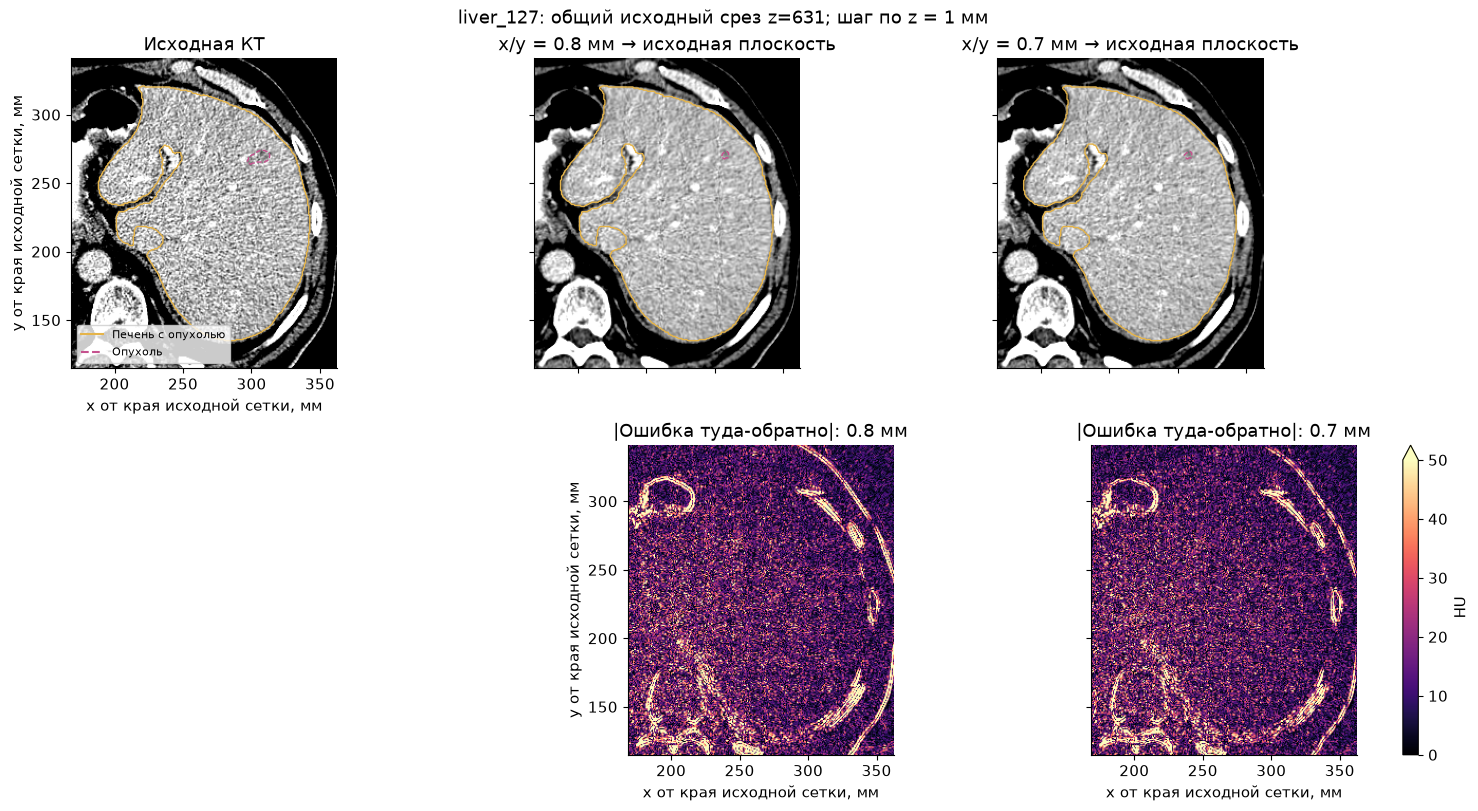

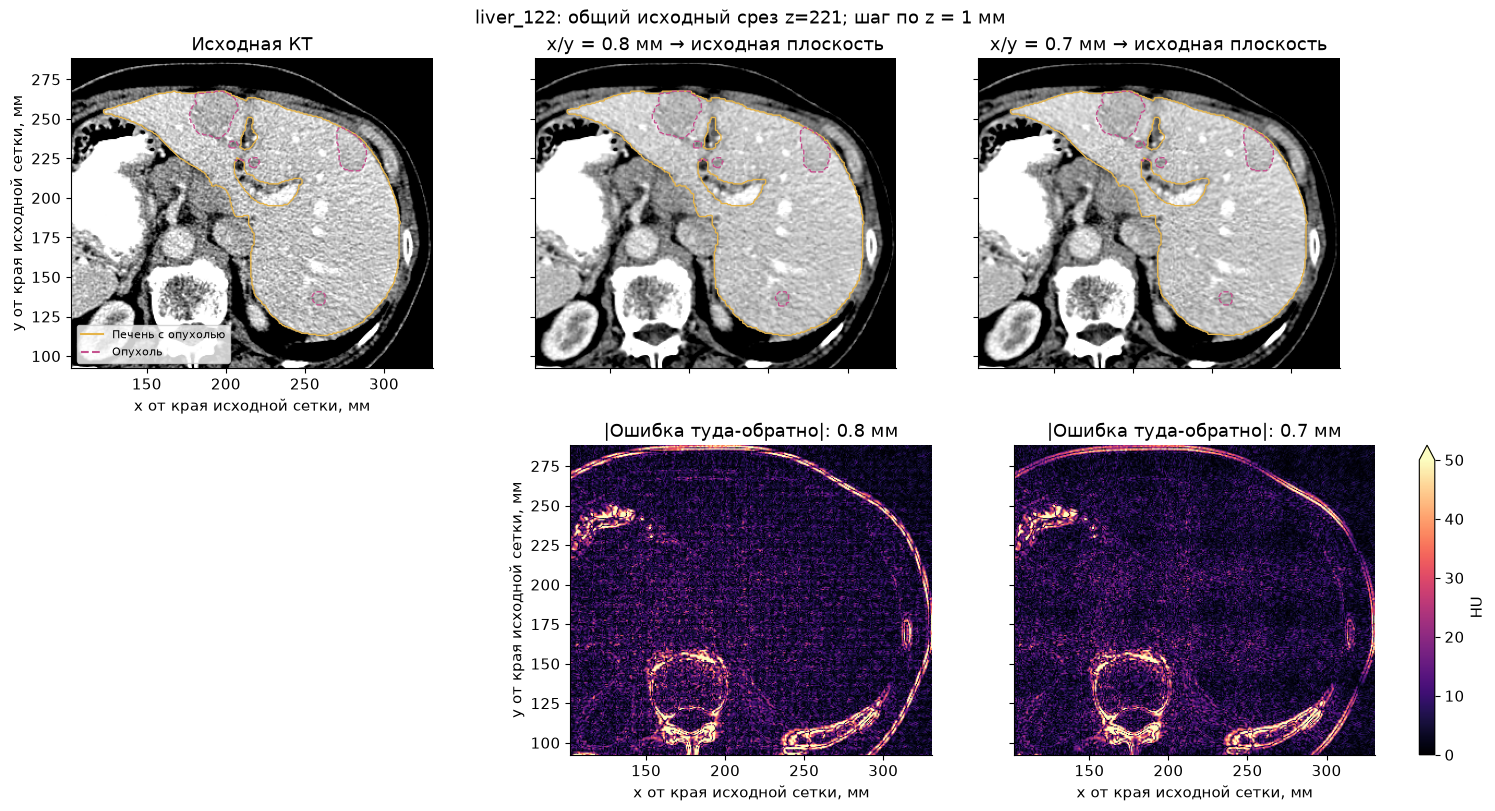

In [42]:
for example in resample_examples:
    sx, sy, sz = example['spacing']
    x0, y0 = example['start']
    x1, y1 = example['stop']
    extent = [x0 * sx, x1 * sx, y0 * sy, y1 * sy]
    x_centers = (np.arange(x0, x1) + 0.5) * sx
    y_centers = (np.arange(y0, y1) + 0.5) * sy
    fig, axes = plt.subplots(
        2, 3, figsize=(15, 8), sharex=True, sharey=True, layout='constrained',
    )
    versions = [('Исходная КТ', example['before'], example['mask_before'])]
    versions += [
        (
            f'x/y = {step:.1f} мм → исходная плоскость',
            example['variants'][step]['after'],
            example['variants'][step]['mask_after'],
        )
        for step in TARGET_SPACINGS
    ]
    for ax, (title, plane, plane_mask) in zip(axes[0], versions):
        ax.imshow(
            plane.T, cmap='gray', origin='lower', extent=extent,
            vmin=RESAMPLE_WINDOW[0], vmax=RESAMPLE_WINDOW[1],
        )
        for region, color, style in [
            (plane_mask > 0, '#E5B44A', '-'),
            (plane_mask == 2, '#C5528E', '--'),
        ]:
            if region.any() and not region.all():
                ax.contour(
                    x_centers, y_centers, region.T, levels=[0.5],
                    colors=[color], linestyles=[style], linewidths=1,
                )
        ax.set_title(title)
    for ax, step_xy in zip(axes[1, 1:], TARGET_SPACINGS):
        error = np.abs(example['variants'][step_xy]['after'] - example['before'])
        error_map = ax.imshow(
            error.T, cmap='magma', origin='lower', extent=extent,
            vmin=0, vmax=ERROR_MAX_HU,
        )
        ax.set_title(f'|Ошибка туда-обратно|: {step_xy:.1f} мм')
        ax.set_xlabel('x от края исходной сетки, мм')
    fig.colorbar(error_map, ax=list(axes[1, 1:]), label='HU', extend='max')
    axes[1, 0].set_visible(False)
    axes[0, 0].set(
        xlabel='x от края исходной сетки, мм', ylabel='y от края исходной сетки, мм',
    )
    axes[0, 0].tick_params(labelbottom=True)
    axes[1, 1].set_ylabel('y от края исходной сетки, мм')
    axes[1, 1].tick_params(labelleft=True)
    axes[0, 0].plot([], [], color='#E5B44A', label='Печень с опухолью')
    axes[0, 0].plot([], [], color='#C5528E', linestyle='--', label='Опухоль')
    axes[0, 0].legend(loc='lower left', fontsize=8)
    fig.suptitle(f"{example['case_id']}: общий исходный срез z={example['z']}; шаг по z = 1 мм")
    plt.show()
    plt.close(fig)

В обоих примерах ошибка HU ниже при 0,7 мм. Однако у `liver_127`
опухоль объёмом 0,124 мл теряет около 46–48% объёма при обоих шагах.
Средние результаты не описывают такие крайние случаи.

## Итог

Данные полны; после учёта поправок IRCAD геометрия КТ и масок согласована.
При подготовке данных нужно учитывать разные шаги и размеры КТ, а также отличие test по шагу z.

Опухоль занимает малую часть изображения: медианная доля во всей КТ — 0,017%,
а в 13 исследованиях её метка отсутствует. HU помогают различать ткани,
но их распределения перекрываются — одного порога недостаточно.

Сетка **0,7 × 0,7 × 1 мм** не много лучше сохраняет маски по Dice и теряет на один мелкий компонент меньше,
чем **0,8 × 0,8 × 1 мм**. При этом ошибка объёма не улучшается по всем показателям,
а маленькие объекты могут сильно измениться при обоих шагах.
Поэтому разумно остановится на **0,8 × 0,8 × 1 мм** для будущего обучения, как на компромиссном варианте.